<a href="https://colab.research.google.com/github/EnriqueDiaz2/Modelo-LSTM-Bidireccional/blob/main/LSTM_Bidireccional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
!pip install gensim

In [46]:
!git clone https://github.com/parth06/Fake-News-Challenge.git

Cloning into 'Fake-News-Challenge'...
remote: Enumerating objects: 268, done.
remote: Total 268 (delta 0), reused 0 (delta 0), pack-reused 268 (from 1)
Receiving objects: 100% (268/268), 4.48 MiB | 8.61 MiB/s, done.
Resolving deltas: 100% (137/137), done.


In [47]:
cd Fake-News-Challenge/

/content/Fake-News-Challenge/Fake-News-Challenge


In [49]:
#!git submodule init
#!git submodule update

In [50]:
"""
glove.twitter.27B.zip
glove.6B.zip
Estos archivos contienen vectores preentrenados (embeddings) de palabras usando
el método GloVe (Global Vectors for Word Representation). Estos vectores permiten
representar cada palabra como un vector numérico en un espacio de alta dimensión,
de modo que relaciones semánticas y de similaridad entre palabras puedan
capturarse de forma matemática.

"""

!mkdir data/glove
!mkdir data/glove_twitter

!wget http://nlp.stanford.edu/data/glove.twitter.27B.zip
!wget http://nlp.stanford.edu/data/glove.6B.zip

!unzip glove.twitter.27B.zip -d data/glove_twitter/
!unzip glove.6B.zip -d data/glove

--2026-10-20 00:05:47--  http://nlp.stanford.edu/data/glove.twitter.27B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.twitter.27B.zip [following]
--2026-10-20 00:05:47--  https://nlp.stanford.edu/data/glove.twitter.27B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.twitter.27B.zip [following]
--2026-10-20 00:05:47--  https://downloads.cs.stanford.edu/nlp/data/glove.twitter.27B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1520408563 (1.4G) [ap

In [51]:
#Eliminar los archivos comprimidos
!rm glove.twitter.27B.zip
!rm glove.6B.zip

In [52]:
import gensim
import numpy as np
import pandas as pd
import os


"""
La librería GloVe (Global Vectors for Word Representation) de Stanford distribuye
los embeddings en un formato de texto distinto al que Gensim entiende.

La función glove2word2vec convierte un archivo de embeddings GloVe (por ejemplo,
glove.6B.100d.txt) al formato Word2Vec que Gensim puede cargar directamente.
"""
from gensim.scripts.glove2word2vec import glove2word2vec

"""
KeyedVectors es la clase de Gensim que permite cargar y trabajar con embeddings
de palabras (ya sea entrenados en Word2Vec o convertidos desde GloVe).
Una vez cargados, puedes:
-Obtener vectores de palabras.
-Calcular similitudes entre palabras.
-Buscar las palabras más cercanas en el espacio vectorial.
"""
from gensim.models import KeyedVectors

from tensorflow.keras import callbacks
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, BatchNormalization, Bidirectional
from tensorflow.keras.layers import concatenate,subtract
"""
concatenate - Une (concatena) varios tensores a lo largo de un eje.
Para qué sirve:
Fusionar diferentes representaciones de entrada.
Combinar salidas de distintas capas (por ejemplo, una CNN y una LSTM).
subtract - Calcula la resta elemento a elemento entre dos tensores de la misma forma.
Para qué sirve:
Capturar diferencias entre dos representaciones.
Muy común en redes siamesas (comparación de embeddings, ver qué tan similares/diferentes son).
"""
from tensorflow.keras.preprocessing.text import text_to_word_sequence, Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

%matplotlib inline
from matplotlib import pyplot as plt
from tensorflow.keras.utils import plot_model
from IPython.display import Image
#import pydot

# LaberEncoder Convierte cada categoría en un número entero único.
# Por ejemplo, si tienes etiquetas de texto como
# ["rojo", "verde", "azul", "verde"], las transforma en algo como [2, 1, 0, 1].
from sklearn.preprocessing import LabelEncoder

# to categorical - Toma un vector de enteros que representan clases
# (por ejemplo, [0, 1, 2, 1]).
# Devuelve una matriz donde cada entero se convierte en un vector binario con un
# 1 en la posición de la clase y 0 en las demás.
from tensorflow.keras.utils import to_categorical

In [53]:
# Indicar los directorios de los recursos a utilizar para vectorizar
#W2V_DIR = './data/GoogleNews-vectors-negative300.bin' #
GloVe_DIR = './data/glove_twitter/glove.twitter.27B.100d.txt'
# Directorio de los datos de las noticias falsas
DATA_DIR = './data/old'

# Espacio embebido con 100 dimensiones
LSTM_DIM = 100
EMBEDDING_DIM = 100 #100 para GloVe
BATCH_SIZE = 128
N_EPOCHS = 40

In [54]:
# Leer los archivos de texto de Fake News Challenge (FNC)
bodies = pd.read_csv(DATA_DIR + '/body_id.csv')
train_df = pd.read_csv(DATA_DIR + '/train.csv')
validation_df = pd.read_csv(DATA_DIR + '/validation.csv')
test_df = pd.read_csv(DATA_DIR + '/test.csv')

In [55]:
print(f"Número de cuerpos de noticias: {len(bodies)}")
train_df.tail()

Número de cuerpos de noticias: 2587


,Headline,Body ID,Stance
40345,Indian 'Rapist' Castrated By Angry Mob Who Hac...,1760,unrelated
40346,Urgent: The Leader of ISIL 'Abu Bakr al-Baghda...,1681,unrelated
40347,Brian Williams slams social media for speculat...,2419,unrelated
40348,Mexico Says Missing Students Not Found In Firs...,1156,agree
40349,Shots Heard In Alleged Brown Shooting Recordin...,2044,unrelated


In [56]:
train_df.replace('unrelated',1,inplace=True)
train_df.replace('agree',2,inplace=True)
train_df.replace('disagree',3,inplace=True)
train_df.replace('discuss',4,inplace=True)

validation_df.replace('unrelated',1,inplace=True)
validation_df.replace('agree',2,inplace=True)
validation_df.replace('disagree',3,inplace=True)
validation_df.replace('discuss',4,inplace=True)

/tmp/ipykernel_522/5784279.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df.replace('discuss',4,inplace=True)
/tmp/ipykernel_522/5784279.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_df.replace('discuss',4,inplace=True)


In [57]:
# Revisamos el contenido del cuerpo de las noticias y el número de caracteres
print(bodies["articleBody"][0])
print(len(bodies["articleBody"][0]))
len(bodies)

A small meteorite crashed into a wooded area in Nicaragua's capital of Managua overnight, the government said Sunday. Residents reported hearing a mysterious boom that left a 16-foot deep crater near the city's airport, the Associated Press reports. 

Government spokeswoman Rosario Murillo said a committee formed by the government to study the event determined it was a "relatively small" meteorite that "appears to have come off an asteroid that was passing close to Earth." House-sized asteroid 2014 RC, which measured 60 feet in diameter, skimmed the Earth this weekend, ABC News reports. 
Murillo said Nicaragua will ask international experts to help local scientists in understanding what happened.

The crater left by the meteorite had a radius of 39 feet and a depth of 16 feet,  said Humberto Saballos, a volcanologist with the Nicaraguan Institute of Territorial Studies who was on the committee. He said it is still not clear if the meteorite disintegrated or was buried.

Humberto Garcia

2587

In [58]:
# Manejaremos sólo 2 clases, Relacionado y No Relacionado
#Unrelated:0 Related:1
"""
def f(row):
    if row['Stance']==4:
      return 1
    else:
      return 0

train_df['Classify'] = train_df.apply(f, axis=1)
validation_df['Classify'] = validation_df.apply(f, axis=1)
"""

"\ndef f(row):\n    if row['Stance']==4:\n      return 1\n    else:\n      return 0\n\ntrain_df['Classify'] = train_df.apply(f, axis=1)\nvalidation_df['Classify'] = validation_df.apply(f, axis=1)\n"

In [59]:
train_df.tail()

,Headline,Body ID,Stance
40345,Indian 'Rapist' Castrated By Angry Mob Who Hac...,1760,1
40346,Urgent: The Leader of ISIL 'Abu Bakr al-Baghda...,1681,1
40347,Brian Williams slams social media for speculat...,2419,1
40348,Mexico Says Missing Students Not Found In Firs...,1156,2
40349,Shots Heard In Alleged Brown Shooting Recordin...,2044,1


In [60]:
# Toma el DataFrame de la izquierda (train_df, validation_df, o test_df) y le agrega
# columnas del DataFrame bodies, buscando coincidencias en "Body ID"

combine_df_train = train_df.join(bodies.set_index('Body ID'), on='Body ID')
combine_df_validation = validation_df.join(bodies.set_index('Body ID'), on='Body ID')
combine_df_test = test_df.join(bodies.set_index('Body ID'), on='Body ID')

In [61]:
combine_df_train.tail()

,Headline,Body ID,Stance,articleBody
40345,Indian 'Rapist' Castrated By Angry Mob Who Hac...,1760,1,"Money makes the world go round, right?\n\nLunc..."
40346,Urgent: The Leader of ISIL 'Abu Bakr al-Baghda...,1681,1,(CNN) -- Boko Haram laughed off Nigeria's anno...
40347,Brian Williams slams social media for speculat...,2419,1,Along with unveiling the Apple Watch earlier t...
40348,Mexico Says Missing Students Not Found In Firs...,1156,2,The bodies found in a mass grave were confirme...
40349,Shots Heard In Alleged Brown Shooting Recordin...,2044,1,A married TV actor who met a young woman and k...


In [62]:
# Convertimos el texto en secuencias de paralabras, Ejemplo
#Headline: "El gato corre por la casa"
#  ['El', 'gato', 'corre', ...]

word_seq_head_train = [text_to_word_sequence(head) for head in combine_df_train['Headline']]
word_seq_bodies_train = [text_to_word_sequence(body) for body in combine_df_train['articleBody']]
word_seq_head_validation = [text_to_word_sequence(head) for head in combine_df_validation['Headline']]
word_seq_bodies_validation = [text_to_word_sequence(body) for body in combine_df_validation['articleBody']]
word_seq_head_test = [text_to_word_sequence(head) for head in combine_df_test['Headline']]
word_seq_bodies_test = [text_to_word_sequence(body) for body in combine_df_test['articleBody']]

In [63]:
"""
Vamos a recorrer todas las secuencias tokenizadas de titulares (word_seq_head_train).
Calcular la longitud de cada secuencia (cuántas palabras tiene).
Devuelver una lista de enteros que indican las logitudes de cada secuencia.
Toma esas longitudes y calcula el percentil 90.
El percentil 90 significa: el 90% de los titulares tienen esa longitud o menos.
Sirve para saber qué tan largos son la mayoría de los titulares.
"""

print('90% de los encabezados tienen una longitud:', np.percentile([len(seq) for seq in word_seq_head_train], 90))
print('50% de los cuerpos de noticias tienen una longitud:', np.percentile([len(seq) for seq in word_seq_bodies_train], 50))

90% de los encabezados tienen una longitud: 16.0
50% de los cuerpos de noticias tienen una longitud: 308.0


In [64]:
# Esta lista de palabras es para creer nuestro diccionario de palabras.
# Unimos en una sola lista todas las secuencias de palabras de titulares (encabezados)
# y cuerpos de las noticias.

word_seq = []
for i in range(len(word_seq_head_train)):
    word_seq.append(word_seq_head_train[i])
for i in range(len(word_seq_bodies_train)):
    word_seq.append(word_seq_bodies_train[i])

for i in range(len(word_seq_head_validation)):
    word_seq.append(word_seq_head_validation[i])
for i in range(len(word_seq_bodies_validation)):
    word_seq.append(word_seq_bodies_validation[i])

for i in range(len(word_seq_head_test)):
    word_seq.append(word_seq_head_test[i])
for i in range(len(word_seq_bodies_test)):
    word_seq.append(word_seq_bodies_test[i])

In [65]:
# Ubicamos paralabras unicas para definir el tamaño del vocabulario
# lista de caracteres a eliminar
filter_list = '!"\'#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'
# Limita el vocabulario a las 25,000 palabras más frecuentes del dataset.
MAX_VOCAB_SIZE = 25000
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, filters=filter_list)
tokenizer.fit_on_texts([seq for seq in word_seq])

# Encuentra la cantidad de palabras unicas sin importar que se vayan a usar menos
print("Número de palabras en el vocabulario:", len(tokenizer.word_index))
# Número máximo de palabras a utilizar
print("Palabras del vocabulario que se van a utilizar", tokenizer.num_words)

Número de palabras en el vocabulario: 35978
Palabras del vocabulario que se van a utilizar 25000


In [66]:
# Cargar el word2vec embeddings
#embeddings = gensim.models.KeyedVectors.load_word2vec_format(GloVe_DIR, binary=True)

# Cargar GloVes
glove_input_file = GloVe_DIR
# Cargamos la representación GloVes con un embebido de 50 dimensiones
# lo convertimos al formato word2vec y lo guardamos
word2vec_output_file = 'glove.100d.txt.word2vec'
glove2word2vec(glove_input_file, word2vec_output_file)

# En versiones futuras de la librería ya no existirá "glove2word2vec" por lo que se reemplazará con:
# model.save_word2vec_format(word2vec_output_file, binary=False)
# model = KeyedVectors.load_word2vec_format(glove_input_file, binary=False, no_header=True)

# El archivo gruardado con el formato word2vec es cargado en memoria
embeddings = gensim.models.KeyedVectors.load_word2vec_format(word2vec_output_file, binary=False)

/tmp/ipykernel_522/3358072700.py:9: DeprecationWarning: Call to deprecated `glove2word2vec` (KeyedVectors.load_word2vec_format(.., binary=False, no_header=True) loads GLoVE text vectors.).
  glove2word2vec(glove_input_file, word2vec_output_file)


In [67]:
# Creamos una matriz de tamaño:
# (número de palabras en el vocabulario+1)×(dimensión del embedding)
# inicializando todos los valores aleatoriamente en el rango -0.05, 0.05.

np.random.seed(1)
# El +1 es porque el indice de la matriz inicia en 0
embeddings_matrix = np.random.uniform(-0.05, 0.05, size=(len(tokenizer.word_index)+1, EMBEDDING_DIM))


"""embeddings es un diccionario con vectores preentrenados (por ejemplo, cargado desde GloVe o Word2Vec).
embeddings["king"] → [0.128, -0.532, ..., 0.044]
Si la palabra existe en los embeddings preentrenados, se reemplaza el vector inicial (aleatorio) por el vector real.
Si no existe (KeyError), se deja el vector aleatorio.
"""
for word, i in tokenizer.word_index.items(): # i=0 es el embedding del padding
  try:
      embeddings_vector = embeddings[word]
  except KeyError:
      embeddings_vector = None
  if embeddings_vector is not None:
      embeddings_matrix[i] = embeddings_vector

#del embeddings

In [69]:
"""
Se define un máximo de palabras para cada secuencia:
MAX_HEAD_LEN = 15 → Cada titular (headline) se corta o rellena a 15 palabras.
MAX_BODY_LEN = 300 → Cada cuerpo de texto (body) se corta o rellena a 300 palabras.
"""

MAX_HEAD_LEN = 15
MAX_BODY_LEN = 300

# Convierte la secuencia de palabras a una secuencia de indices
X_head_train = tokenizer.texts_to_sequences([' '.join(seq[:MAX_HEAD_LEN]) for seq in word_seq_head_train])
# Acorta las frases a una longitud fija
# Si la secuencia es más corta que 15 → añade ceros (0) al final.
# Si es más larga → la corta al final.
X_head_train = pad_sequences(X_head_train, maxlen=MAX_HEAD_LEN, padding='post', truncating='post')

X_body_train = tokenizer.texts_to_sequences([' '.join(seq[:MAX_BODY_LEN]) for seq in word_seq_bodies_train])
X_body_train = pad_sequences(X_body_train, maxlen=MAX_BODY_LEN, padding='post', truncating='post')

# Etiquetas de entrenamiento
y_stance_train = combine_df_train['Stance']
#y_classify_train = combine_df_train['Classify']


#Validation
X_head_val = tokenizer.texts_to_sequences([' '.join(seq[:MAX_HEAD_LEN]) for seq in word_seq_head_validation])
X_head_val = pad_sequences(X_head_val, maxlen=MAX_HEAD_LEN, padding='post', truncating='post')

X_body_val = tokenizer.texts_to_sequences([' '.join(seq[:MAX_BODY_LEN]) for seq in word_seq_bodies_validation])
X_body_val = pad_sequences(X_body_val, maxlen=MAX_BODY_LEN, padding='post', truncating='post')

y_stance_val = combine_df_validation['Stance']
#y_classify_val = combine_df_validation['Classify']

#TEST
# Convert the sequence of words to sequnce of indices
X_head_test = tokenizer.texts_to_sequences([' '.join(seq[:MAX_HEAD_LEN]) for seq in word_seq_head_test])
X_head_test = pad_sequences(X_head_test, maxlen=MAX_HEAD_LEN, padding='post', truncating='post')

X_body_test = tokenizer.texts_to_sequences([' '.join(seq[:MAX_BODY_LEN]) for seq in word_seq_bodies_test])
X_body_test = pad_sequences(X_body_test, maxlen=MAX_BODY_LEN, padding='post', truncating='post')

In [70]:
# Esto es lo que paso en la anterior celda, pasamos de una secuencia de palabras a una
# secuencia de indices
print(word_seq_head_train[0])
print(X_head_train[0])

['hundreds', 'of', 'palestinians', 'flee', 'floods', 'in', 'gaza', 'as', 'israel', 'opens', 'dams']
[1273    4 6854 3105 9719    5 2439   16  951 7468 6216    0    0    0
    0]


In [71]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# -----------------------------
# Codificar etiquetas stance
# -----------------------------
encoder_train = LabelEncoder()
encoder_train.fit(y_stance_train)

encoded_train = encoder_train.transform(y_stance_train)
encoded_val   = encoder_train.transform(y_stance_val)

# Codificación One-hot
dummy_ys_train = to_categorical(encoded_train)
dummy_ys_val   = to_categorical(encoded_val)

# -----------------------------
# Codificar etiquetas classify
# -----------------------------
"""encoder_train = LabelEncoder()
encoder_train.fit(y_classify_train)

encoded_train = encoder_train.transform(y_classify_train)
encoded_val   = encoder_train.transform(y_classify_val)

# Codificación One-hot
dummy_yc_train = to_categorical(encoded_train)
dummy_yc_val   = to_categorical(encoded_val)
"""

'encoder_train = LabelEncoder()\nencoder_train.fit(y_classify_train)\n\nencoded_train = encoder_train.transform(y_classify_train)\nencoded_val   = encoder_train.transform(y_classify_val)\n\n# Codificación One-hot\ndummy_yc_train = to_categorical(encoded_train)\ndummy_yc_val   = to_categorical(encoded_val)\n'

In [72]:
print(dummy_ys_train[0])
#print(dummy_yc_train[0])

[0. 1. 0. 0.]


In [73]:
print(len(X_body_train[1]))
len(X_head_train[1])

300


15

In [74]:
from tensorflow.keras.layers import Input, add

# Define las capas de entrada
head_input = Input(shape=(MAX_HEAD_LEN,), name='head_input')
body_input = Input(shape=(MAX_BODY_LEN,), name='body_input')

# Construye un modelo secuencial para el encabezado head
left = Sequential()
left.add(Embedding(input_dim=len(tokenizer.word_index)+1,
                          output_dim=EMBEDDING_DIM,
                          weights = [embeddings_matrix], trainable=False, name='head_word_embedding_layer', #False
                          mask_zero=True))
left.add(Bidirectional(LSTM(LSTM_DIM, return_sequences=False, name='head_Bidrectional_lstm_layer1')))

# Construye un modelo secuencial para el cuerpo body
right = Sequential()
right.add(Embedding(input_dim=len(tokenizer.word_index)+1,
                          output_dim=EMBEDDING_DIM,
                          weights = [embeddings_matrix], trainable=False, name='body_word_embedding_layer', #False
                          mask_zero=True))
right.add(Bidirectional(LSTM(LSTM_DIM, return_sequences=False, name='body_Bidrectional_lstm_layer2')))

# Concatenamos a los modelos secuenciales con sus capas de entrada
concatenated = concatenate([left(head_input),right(body_input)])

# Iniciamos la sección de capas densas
layer_1 = Dense(100, activation='relu', name='layer_1') (concatenated)
dropout_1 = Dropout(rate=0.5, name='dropout_1')(layer_1)
layer_2 =Dense(50,  activation='relu', name='layer_2') (dropout_1)
dropout_2 = Dropout(rate=0.5, name='dropout_2')(layer_2)
# layer_3 =Dense(600,  activation='relu', name='layer_3') (dropout_2)
# dropout_3 = Dropout(rate=0.5, name='dropout_3')(layer_3)
# out1 =  Dense(2, activation='softmax', name='output_layer1')(dropout_3)
out2 = Dense(4, activation='softmax', name='output_layer2')(dropout_2)

model = Model([head_input, body_input], out2) # Usa las capas de entrada

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ head_input          │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ body_input          │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 200)       │  3,758,700 │ head_input[0][0]  │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 200)       │  3,758,700 │ body_input[0][0]  │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 400)       │          0 │ sequential_2[0][… │
│ (Concatenate)       │                   │            │ sequential_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_1 (Dense)     │ (None, 100)       │     40,100 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 100)       │          0 │ layer_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_2 (Dense)     │ (None, 50)        │      5,050 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 50)        │          0 │ layer_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer2       │ (None, 4)         │        204 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,562,754 (28.85 MB)

 Trainable params: 366,954 (1.40 MB)

 Non-trainable params: 7,195,800 (27.45 MB)

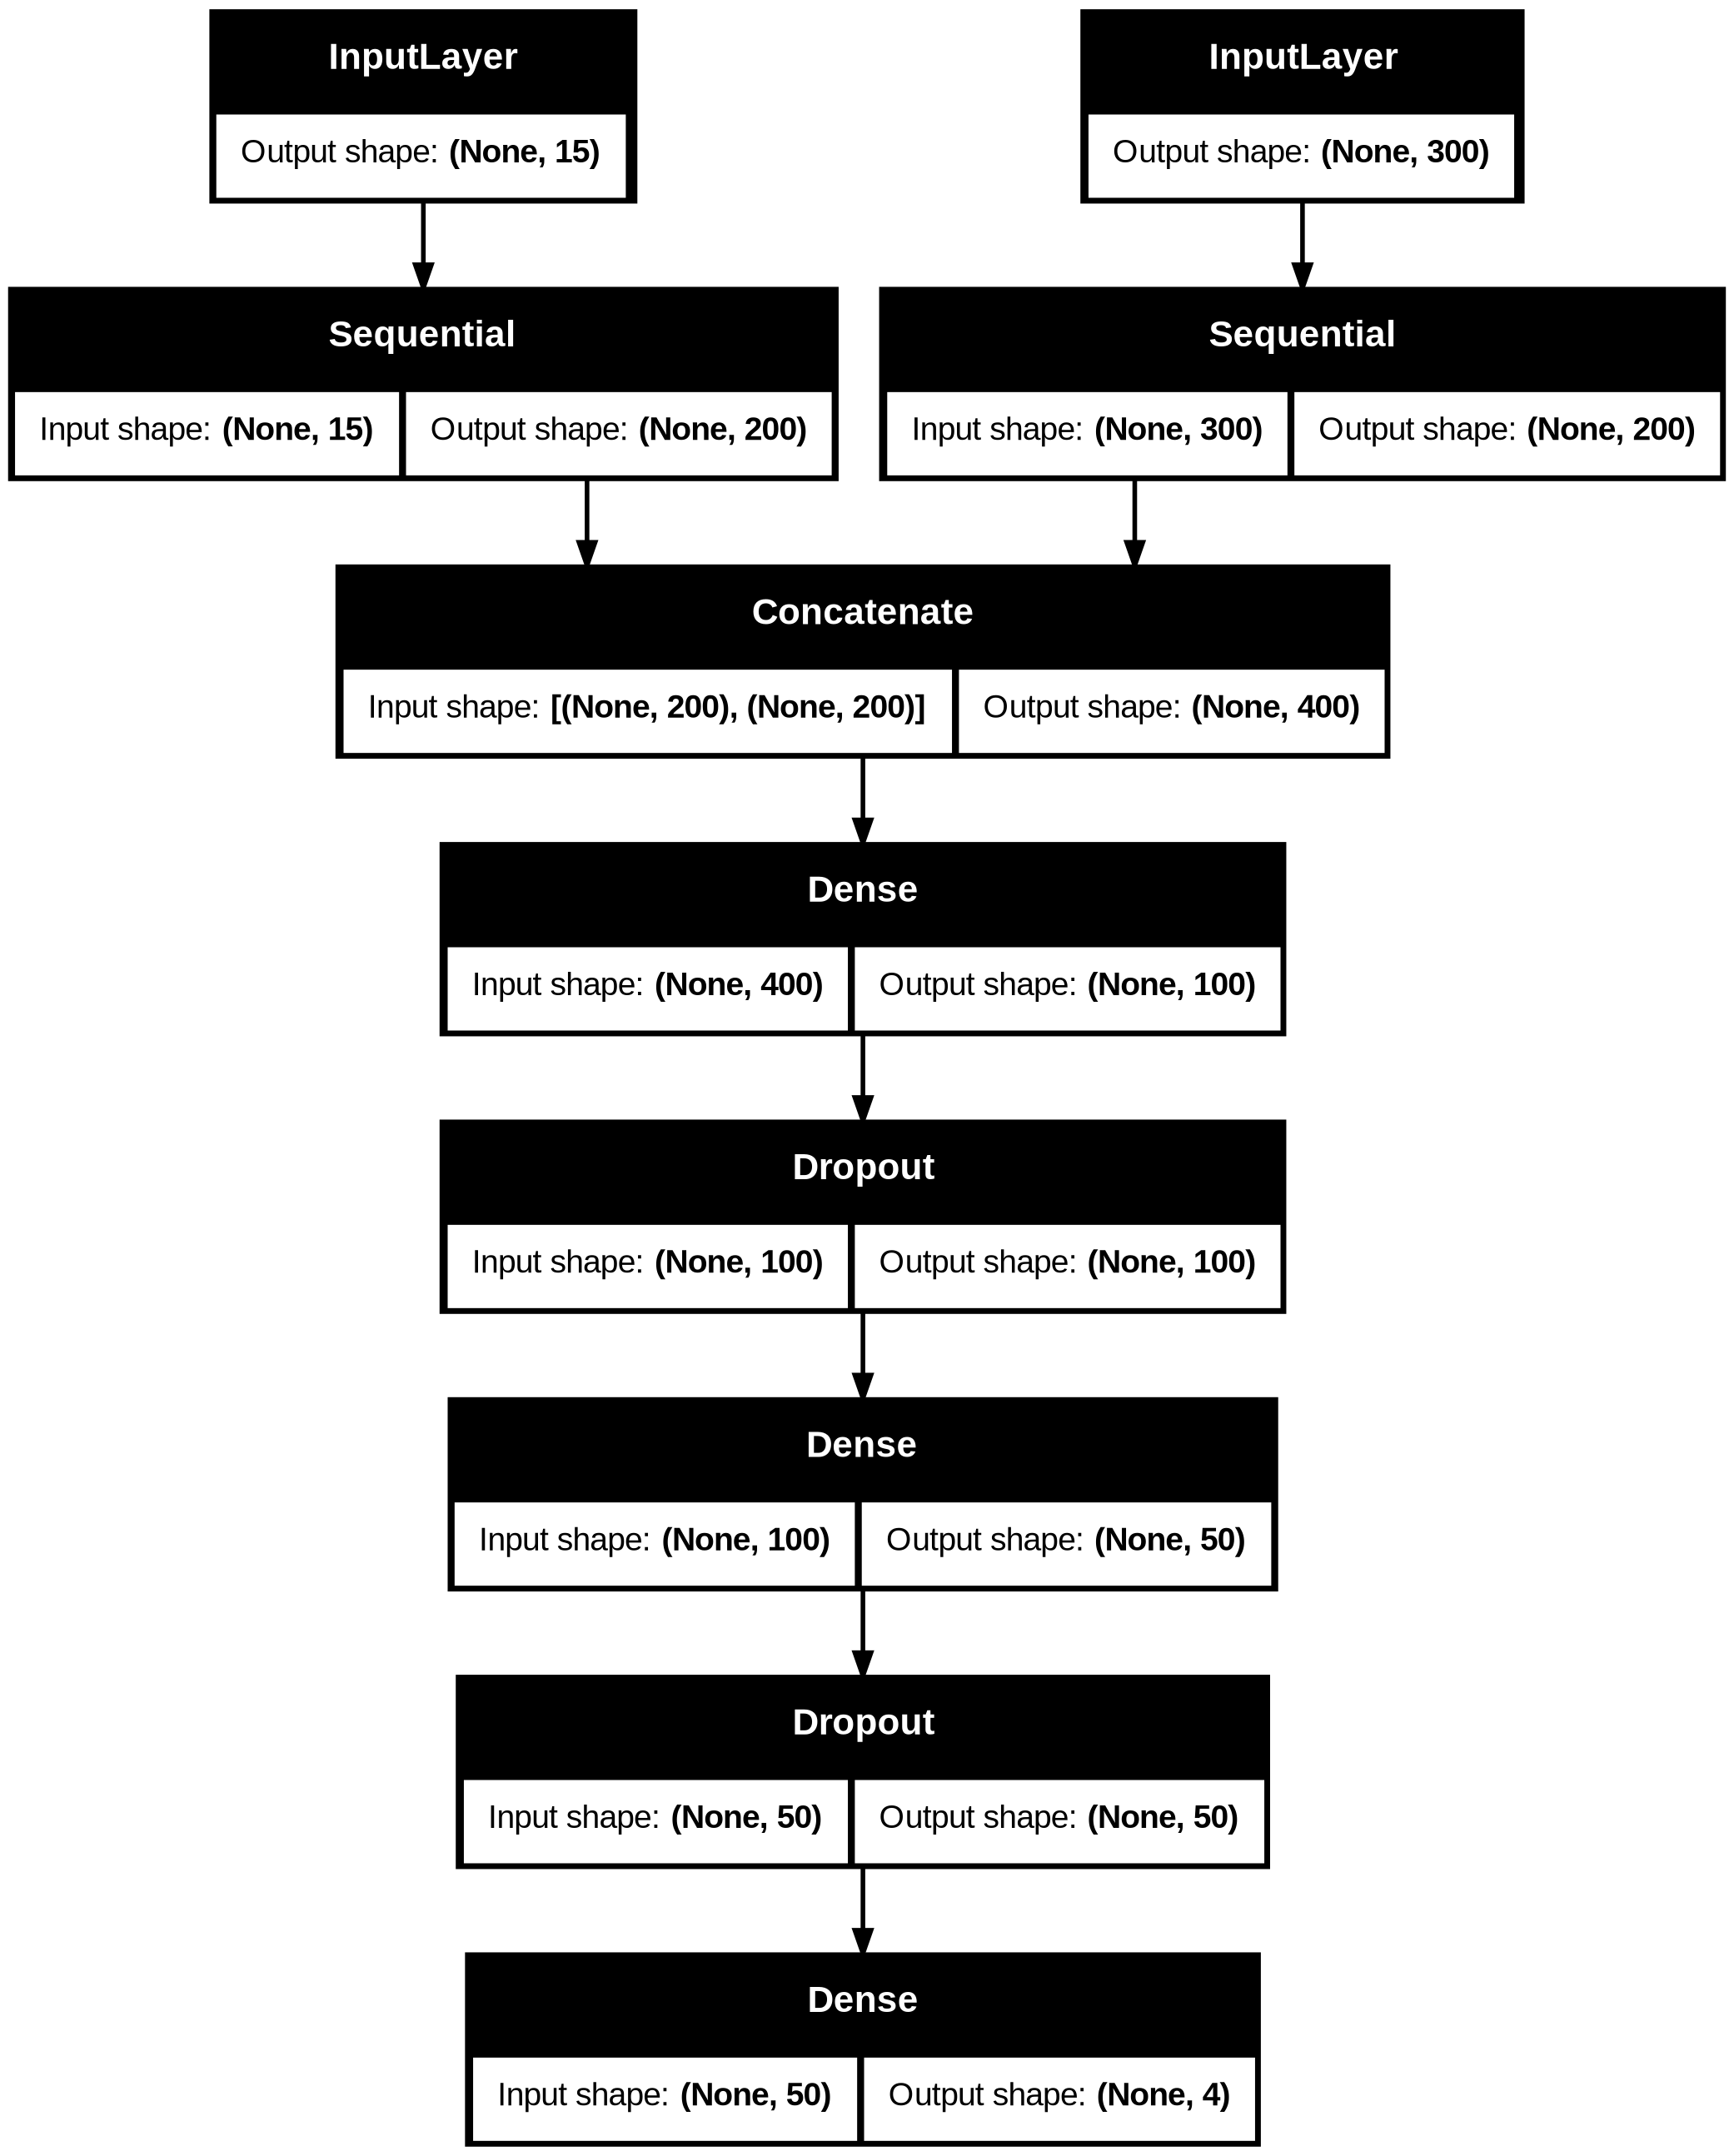

In [75]:
from keras.utils import plot_model
plot_model(model, show_shapes=True)

In [76]:
# filepath="./result/lstmBidirectional_lstm_50token_lr0.001_trainable_{epoch:02d}_{val_acc:.4f}.h5"
# checkpoint = callbacks.ModelCheckpoint(filepath,
#                                        monitor='val_acc',
#                                        verbose=0,
#                                        save_best_only=True)
es = callbacks.EarlyStopping(monitor='val_acc', mode='max',patience=2)
callbacks_list1 = [es]

In [77]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [78]:
history = model.fit([X_head_train,X_body_train], y = dummy_ys_train,
          batch_size=BATCH_SIZE,
          epochs=N_EPOCHS,
                    verbose=1,
          validation_data=([X_head_val,X_body_val], dummy_ys_val),callbacks = callbacks_list1)

Epoch 1/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.7387 - loss: 0.7533 - val_accuracy: 0.7399 - val_loss: 0.6330
Epoch 2/40
  5/316 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.7525 - loss: 0.6006

/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_acc` which is not available. Available metrics are: accuracy,loss,val_accuracy,val_loss
  current = self.get_monitor_value(logs)


316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.7946 - loss: 0.5187 - val_accuracy: 0.7645 - val_loss: 0.5886
Epoch 3/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8496 - loss: 0.3909 - val_accuracy: 0.7836 - val_loss: 0.5395
Epoch 4/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8847 - loss: 0.3053 - val_accuracy: 0.8064 - val_loss: 0.5191
Epoch 5/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9133 - loss: 0.2383 - val_accuracy: 0.8168 - val_loss: 0.5069
Epoch 6/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.9306 - loss: 0.1922 - val_accuracy: 0.8219 - val_loss: 0.5495
Epoch 7/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.9415 - loss: 0.1613 - val_accuracy: 0.8193 - val_loss: 0.6235
Epoch 8/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9506 - loss: 0.1369 - val_accuracy: 0.8242 - val_loss: 0.5783
Epoch 9/40
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.9564 - loss: 0.1178 - val_accurac

In [79]:
model.evaluate([X_head_val,X_body_val],y=dummy_ys_val)

301/301 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8581 - loss: 1.1473


[1.1473339796066284, 0.8581376075744629]

In [80]:
print(X_head_train.shape)
print(X_body_train.shape)

print(X_head_test.shape)
print(X_body_test.shape)
print(X_head_test[0])
print(X_body_test[0])

(40350, 15)
(40350, 300)
(25413, 15)
(25413, 300)
[ 531 8183 1291  128 6765 1317   37 3546  540 5920 1507 1633  178  403
 2314]
[    3  4687   534  1116    89   329  1269     1  1494  2119   908  2333
   182    18   272   162  7183   535    37     1  2956   501  2906     1
   180  1658  3231  2089  2100   600     3  1156    10   436     5    18
    89   290     5  3269    81   308   295    95  1476   488     3  2932
   167    18   394    23  8802    10   442     1   161    37   130  2160
   497    23     1  2031   908    76   290     6   193   332    64   269
   822     2   136   784  1447  1413   312     1  1881     4  5110     4
     1   257    89   205   163  2089    32   196    18   272   162     5
     3   202   191    37    18   139     3  1881   322    14    13     8
    12   839  6972     7    40    38  2654    28   519     4     1   139
     4   136  2932  3231  2089  4538    16  1460   450     4     1  1897
   222  3319    89     5  3269    10    28  1596   161     4   257  4

In [81]:
yt = model.predict([X_head_test,X_body_test])

795/795 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step


In [82]:
yt = np.argmax(yt,axis=1)
ans = pd.DataFrame(yt)
ans.head()

,0
0,0
1,0
2,0
3,0
4,0


In [83]:
ans.replace(0,'unrelated',inplace=True)
ans.replace(1,'agree',inplace=True)
ans.replace(2,'disagree',inplace=True)
ans.replace(3,'discuss',inplace=True)

In [84]:
ans.tail()

,0
25408,unrelated
25409,agree
25410,unrelated
25411,discuss
25412,agree


In [85]:
test_df.tail()

,Headline,Body ID
25408,The success of the Affordable Care Act is a hu...,2582
25409,The success of the Affordable Care Act is a hu...,2583
25410,The success of the Affordable Care Act is a hu...,2584
25411,The success of the Affordable Care Act is a hu...,2585
25412,The success of the Affordable Care Act is a hu...,2586


In [86]:
# Concatena los DataFrames ans y test_df
concatenated_df = pd.concat([test_df, ans], axis=1)

# Mostrar el resultado de la concatenación
concatenated_df.tail()

,Headline,Body ID,0
25408,The success of the Affordable Care Act is a hu...,2582,unrelated
25409,The success of the Affordable Care Act is a hu...,2583,agree
25410,The success of the Affordable Care Act is a hu...,2584,unrelated
25411,The success of the Affordable Care Act is a hu...,2585,discuss
25412,The success of the Affordable Care Act is a hu...,2586,agree


In [87]:
# Guarda el Dataframe concatenado en un archivo CSV
concatenated_df.to_csv('test_results.csv', index=False)